020 - Máquinas de vectores de soporte (SVM)
---

* Algoritmo de aprendizaje supervisado
* Utilizado para tareas de clasificación y regresión
* Capacidad para gestionar conjuntos de datos de alta dimensión
* Busca encontrar el límite de decisión óptimo (hiperplano) que separa los puntos de datos de diferentes clases
* Objetivo es maximizar la distancia entre el hiperplano y los puntos de datos más cercanos de cada clases, conocidos como **vectores de soporte**

## Conceptos

* **Hiperplano**: es un límite de decisión que separa puntos de datos de diferentes clases. En un conjunto de datos 2D, el hiperplano es una línea. En datos 3D, es un plano
* **Margen**: es la distancia entre el hiperplano y los puntos de datos más cercanos de cualquiera de las clases. SVM maximiza este margen para garantizar que el modelo sea sólido
* **Vectores de soporte**: son los puntos de datos más cercanos al hiperplano. La posición de los vectores de soporte determina la orientación y posición del hiperplano
* Cuando los datos no son linealmente separables, SVM utiliza una **función de kernel** para proyectarlos en un espacio de mayor dimensión donde se vuelven linealmente separables

## ¿Cómo funciona SVM?

* **Paso 1: Datos linealmente separables**. Cuando los datos son linealmente separables, SVM encuentra el hiperplano que separa las clases con el mayor margen
* **Paso 2: Datos no linealmente separables**. Cuando los datos no se pueden separar linealmente (por ejemplo, círculos concéntricos), SVM utiliza una función de kernel para mapear los datos a un espacio de mayor dimensión, donde se vuelven separables:
    * lineal, polinomial, radial, sigmoideo

## Ejemplo SVM para clasificación de dígitos escritos a mano

In [6]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt

# Load the MNIST dataset
digits = datasets.load_digits()

# Split data into features and target
X, y = digits.data, digits.target

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize SVM with an RBF kernel (radial)
svm_model = SVC(kernel='rbf', gamma=0.01, C=1.0)

# Train the model
svm_model.fit(X_train, y_train)

# Predict on test data
y_pred = svm_model.predict(X_test)

# Print accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Classification report
print(classification_report(y_test, y_pred))

Accuracy: 0.7055555555555556
              precision    recall  f1-score   support

           0       1.00      0.62      0.77        53
           1       1.00      0.74      0.85        50
           2       1.00      0.74      0.85        47
           3       1.00      0.74      0.85        54
           4       1.00      0.73      0.85        60
           5       1.00      0.45      0.62        66
           6       1.00      0.79      0.88        53
           7       1.00      0.76      0.87        55
           8       0.21      1.00      0.35        43
           9       1.00      0.59      0.74        59

    accuracy                           0.71       540
   macro avg       0.92      0.72      0.76       540
weighted avg       0.94      0.71      0.77       540



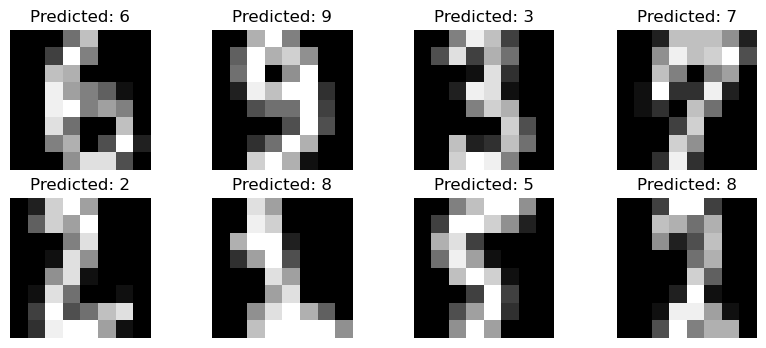

In [7]:
# Visualize some predictions
plt.figure(figsize=(10, 4))
for index, (image, label) in enumerate(zip(X_test[:8], y_pred[:8])):
    plt.subplot(2, 4, index + 1)
    plt.imshow(image.reshape(8, 8), cmap='gray')
    plt.title(f'Predicted: {label}')
    plt.axis('off')
plt.show()